# 05 · Hypothesis testing by role

**Question: does what the game pays for depend on a player's role?** For each role we test a set of attributes that should matter for it. Design choices (see 01 §6 for why):

| Choice | Why |
|---|---|
| Fit each role's model **on that role only** (roles from 03) | A model fit on everyone mixes populations: GK attributes are noise for outfielders |
| `log(value)` target | Coefficients become **% change in value per +1 point**; residuals close to normal |
| **HC3 robust** standard errors | Heteroscedasticity remains |
| Control for age (quadratic) | The age curve is strongly non-linear (04) |
| **Benjamini–Hochberg FDR** across all tests | ~25 tests are run |
| VIFs and **joint** tests; effect sizes with CIs | Collinear attributes (r ≈ 0.95) make individual t-tests weak |

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor

warnings.filterwarnings("ignore")
d = pd.read_csv("../data/player_stats_clean.csv").merge(pd.read_csv("../data/roles.csv"), on=["player", "club", "age"])

# Attribute sets tested for each role
HYPOTHESES = {
    "Striker": (["Striker"], ["dribbling", "vision", "att_position", "ball_control", "reactions"]),
    "Midfielder": (["Playmaker", "Defensive mid"], ["dribbling", "vision", "crossing", "ball_control", "curve"]),
    "Goalkeeper": (["Goalkeeper"], ["gk_positioning", "gk_diving", "gk_handling", "gk_kicking", "gk_reflexes"]),
    "Defender": (["Centre-back", "Fullback"], ["acceleration", "sprint_speed", "slide_tackle", "stand_tackle", "interceptions"]),
}
d.groupby("role").size()

role
Centre-back       903
Defensive mid    1238
Fullback          941
Goalkeeper        632
Playmaker         608
Striker           628
Winger            727
dtype: int64

## Fit: one model per role, log target, age control, HC3

In [2]:
def fit(sub, attrs, target="log_value"):
    return smf.ols(f"{target} ~ {' + '.join(attrs)} + age + I(age**2)", data=sub).fit(cov_type="HC3")


rows, fits = [], {}
for label, (roles, attrs) in HYPOTHESES.items():
    sub = d[d.role.isin(roles)]
    m = fit(sub, attrs)
    fits[label] = (m, sub, attrs)
    ci = m.conf_int()
    for a in attrs:
        rows.append({"model": label, "n": len(sub), "attribute": a,
                     "% value per +1": np.expm1(m.params[a]),
                     "95% CI low": np.expm1(ci.loc[a, 0]), "95% CI high": np.expm1(ci.loc[a, 1]),
                     "p (HC3)": m.pvalues[a]})
res = pd.DataFrame(rows)

### Collinearity check (VIF within each role)

In [3]:
vif = {}
for label, (m, sub, attrs) in fits.items():
    Xv = sub[attrs].assign(const=1.0)
    vif[label] = pd.Series([variance_inflation_factor(Xv.values, i) for i in range(len(attrs))], index=attrs)
pd.concat(vif, axis=1).round(1)

,Striker,Midfielder,Goalkeeper,Defender
dribbling,5.2,4.9,NaN,NaN
vision,2.5,2.9,NaN,NaN
att_position,5.8,NaN,NaN,NaN
ball_control,8.1,5.6,NaN,NaN
reactions,4.7,NaN,NaN,NaN
crossing,NaN,2.8,NaN,NaN
curve,NaN,2.7,NaN,NaN
gk_positioning,NaN,NaN,7.9,NaN
gk_diving,NaN,NaN,6.8,NaN
gk_handling,NaN,NaN,5.9,NaN


VIF > 5–10 means individual t-tests have little power: the data can't separate those attributes' effects. Joint tests below handle this.

### Joint tests for collinear groups
"Does ball control *or* dribbling matter for strikers?" is answerable even when "which one?" is not.

In [4]:
JOINT = [
    ("Striker", "dribbling = ball_control = 0"),
    ("Midfielder", "dribbling = ball_control = 0"),
    ("Midfielder", "crossing = curve = 0"),
    ("Goalkeeper", "gk_positioning = gk_diving = gk_handling = gk_reflexes = 0"),
    ("Defender", "acceleration = sprint_speed = 0"),
    ("Defender", "slide_tackle = stand_tackle = 0"),
]
joint = pd.DataFrame([{"model": mdl, "attribute": f"JOINT: {h.replace(' = 0', '').replace(' = ', ', ')}",
                       "p (HC3)": float(fits[mdl][0].wald_test(h, scalar=True).pvalue), "n": len(fits[mdl][1])}
                      for mdl, h in JOINT])

## Multiple-testing correction across every test in this notebook

In [5]:
allt = pd.concat([res, joint], ignore_index=True)
allt["p (BH-adjusted)"] = multipletests(allt["p (HC3)"], method="fdr_bh")[1]
allt["significant (FDR 5%)"] = allt["p (BH-adjusted)"] < 0.05
fmt = {"% value per +1": "{:+.1%}", "95% CI low": "{:+.1%}", "95% CI high": "{:+.1%}",
       "p (HC3)": "{:.2g}", "p (BH-adjusted)": "{:.2g}"}
allt.style.format(fmt, na_rep="").hide(axis="index")

model,n,attribute,% value per +1,95% CI low,95% CI high,p (HC3),p (BH-adjusted),significant (FDR 5%)
Striker,628,dribbling,+2.8%,+1.9%,+3.7%,7.5e-10,1.2e-09,True
Striker,628,vision,+0.7%,+0.3%,+1.2%,0.0022,0.0026,True
Striker,628,att_position,+6.7%,+5.8%,+7.7%,1.2e-47,3.8e-47,True
Striker,628,ball_control,+4.0%,+2.9%,+5.1%,7.5e-13,1.3e-12,True
Striker,628,reactions,+3.5%,+2.8%,+4.3%,6.2e-21,1.3e-20,True
Midfielder,1846,dribbling,+0.4%,-0.5%,+1.3%,0.38,0.38,False
Midfielder,1846,vision,+2.6%,+1.9%,+3.2%,1.1e-15,2e-15,True
Midfielder,1846,crossing,+2.1%,+1.7%,+2.6%,8e-20,1.6e-19,True
Midfielder,1846,ball_control,+11.6%,+10.5%,+12.7%,9.3e-100,6.1e-99,True
Midfielder,1846,curve,-0.2%,-0.6%,+0.2%,0.29,0.3,False


## Why the per-role design matters
The same hypotheses fit the simple way (on *all* players, raw €, classical standard errors), compared with the per-role design:

In [6]:
naive = []
for label, (roles, attrs) in HYPOTHESES.items():
    m = smf.ols(f"value_m ~ {' + '.join(attrs)}", data=d).fit()
    naive += [{"model": label, "attribute": a, "p_naive": m.pvalues[a], "coef_naive": m.params[a]} for a in attrs]
naive = pd.DataFrame(naive)
naive["pooled design (all players, raw €)"] = np.where(naive.p_naive < 0.05, np.where(naive.coef_naive > 0, "raises", "LOWERS"),
                                                        "not significant")
cmp = allt[~allt.attribute.str.startswith("JOINT")].merge(naive, on=["model", "attribute"])
cmp["per-role design (log, HC3, FDR)"] = [
    (f"raises {e:+.1%}/pt" if e > 0 else "LOWERS") if sig else "not significant"
    for e, sig in zip(cmp["% value per +1"], cmp["significant (FDR 5%)"])]
cmp["differs"] = np.where(cmp["pooled design (all players, raw €)"].str[:5] != cmp["per-role design (log, HC3, FDR)"].str[:5], "⚠", "")
print(f"{(cmp.differs == '⚠').sum()} of {len(cmp)} conclusions differ between the two designs")
cmp[["model", "attribute", "pooled design (all players, raw €)", "per-role design (log, HC3, FDR)", "differs"]].style.hide(axis="index")

11 of 20 conclusions differ between the two designs


model,attribute,"pooled design (all players, raw €)","per-role design (log, HC3, FDR)",differs
Striker,dribbling,not significant,raises +2.8%/pt,⚠
Striker,vision,raises,raises +0.7%/pt,
Striker,att_position,LOWERS,raises +6.7%/pt,⚠
Striker,ball_control,not significant,raises +4.0%/pt,⚠
Striker,reactions,raises,raises +3.5%/pt,
Midfielder,dribbling,LOWERS,not significant,⚠
Midfielder,vision,raises,raises +2.6%/pt,
Midfielder,crossing,not significant,raises +2.1%/pt,⚠
Midfielder,ball_control,raises,raises +11.6%/pt,
Midfielder,curve,not significant,not significant,


### The goalkeeper case, visualised
Fit on all 5,677 players, GK attributes look irrelevant because 89% of the sample are outfielders whose GK stats are noise. Fit on goalkeepers only, they are the main price drivers.

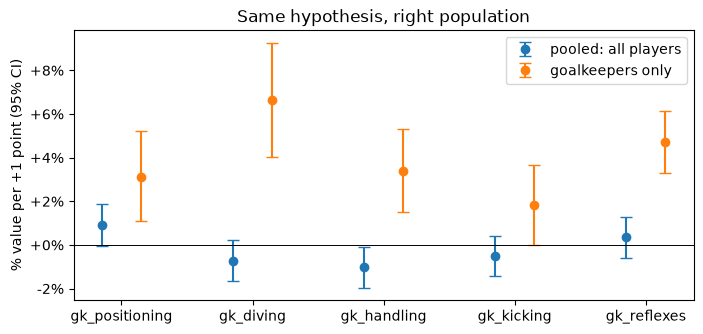

In [7]:
pooled = fit(d, HYPOTHESES["Goalkeeper"][1])
gk = fits["Goalkeeper"][0]
attrs = HYPOTHESES["Goalkeeper"][1]
fig, ax = plt.subplots(figsize=(8, 3.5))
xs = np.arange(len(attrs))
for off, m, lbl in [(-0.15, pooled, "pooled: all players"), (0.15, gk, "goalkeepers only")]:
    est = np.expm1(m.params[attrs])
    ci = np.expm1(m.conf_int().loc[attrs])
    ax.errorbar(xs + off, est, yerr=[est - ci[0], ci[1] - est], fmt="o", capsize=4, label=lbl)
ax.axhline(0, color="k", lw=0.7)
ax.set_xticks(xs, attrs)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:+.0%}")
ax.set_ylabel("% value per +1 point (95% CI)")
ax.legend()
ax.set_title("Same hypothesis, right population");

## Side question: does height drive heading?
Do height and weight matter for heading once jumping is known? Tested on outfield players (heading is irrelevant to a GK's role) with HC3 errors and a joint Wald test:

In [8]:
outf = d[d.is_gk == 0]
hm = smf.ols("heading ~ height + weight + jumping + strength + age", data=outf).fit(cov_type="HC3")
display(hm.summary().tables[1])
print("Joint test height = weight = 0: p =", f"{float(hm.wald_test('height = weight = 0', scalar=True).pvalue):.2g}")

,coef,std err,z,P>|z|,[0.025,0.975]
Intercept,-62.8249,4.258,-14.753,0.000,-71.171,-54.479
height,0.4032,0.028,14.205,0.000,0.348,0.459
weight,0.0087,0.026,0.332,0.740,-0.043,0.060
jumping,0.2560,0.011,22.532,0.000,0.234,0.278
strength,0.3129,0.016,19.606,0.000,0.282,0.344
age,0.3310,0.027,12.367,0.000,0.279,0.383


Joint test height = weight = 0: p = 1.1e-58


## Takeaways
* **What the game pays for depends on role.** The clearest case is goalkeepers: pooled, GK attributes look irrelevant; among goalkeepers, they drive the price.
* **Effect sizes, not just stars.** Coefficients are "% value per point" with confidence intervals, comparable across roles.
* **Collinear groups are tested jointly.** `dribbling` and `ball_control` cannot be told apart individually (high VIF), but jointly they are clearly significant.
* **The design changes the conclusions.** Many conclusions differ between the pooled and per-role designs (⚠ in the comparison table), some with a flipped sign.
* **Height *does* drive heading.** With strength and jumping in the model, each extra cm adds ~0.4 heading points.
* **Caveat:** these are *partial* associations given the other attributes in each model. They describe how the game's formula prices a card, not what causes value in real football.